# Tabular — Analisis Kesalahan Prediksi (di mana dan kenapa model salah?)
**Kapan dipakai:** SETELAH model jadi, sebelum tuning. Hasilnya bahan perbaikan feature dan
slide presentasi.

**Langkah:**
1. Prediksi OOF 5-fold: tiap baris train ditebak oleh model yang tidak melihat baris itu.
2. Kelas mana yang sering tertukar?
3. Irisan data (kategori, rentang angka) mana yang paling sering salah?
4. Baris "yakin tapi salah" (curiga label salah) dan baris ragu (dekat batas kelas).
5. Feature apa yang paling berbeda antara baris salah dan benar?

**Data demo:** KDD Cup 99 (kategori serangan jaringan).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/tabular_extra/ids"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/kdd_train.csv"

TARGET = "kategori"
ID_COL = "id"
CAT_COLS = ["protocol_type", "service", "flag"]
MIN_ROWS = 30            # irisan dengan baris lebih sedikit dari ini tidak ditampilkan
CONFIDENT = 0.9          # "yakin" = probabilitas tebakan ≥ angka ini
DOUBT_GAP = 0.1          # "ragu" = selisih dua kelas teratas < angka ini
SEED = 42

## Baca data
`NUM_COLS` = semua kolom selain id, target, dan kolom kategori.

In [3]:
train = pd.read_csv(TRAIN_CSV)
NUM_COLS = train.columns.drop([ID_COL, TARGET] + CAT_COLS).tolist()
print(train.shape)
train.head()

(15788, 43)


,id,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,kategori
0,9036,0,tcp,ftp,SF,1225,2451,0,0,0,...,116,0.45,0.02,0.00,0.00,0.0,0.0,0.00,0.0,r2l
1,9593,0,tcp,http,SF,242,336,0,0,0,...,255,1.00,0.00,0.00,0.00,0.0,0.0,0.00,0.0,normal
2,14781,2,tcp,smtp,SF,1590,328,0,0,0,...,129,0.38,0.04,0.01,0.02,0.0,0.0,0.00,0.0,normal
3,8616,0,tcp,http,REJ,0,0,0,0,0,...,52,0.88,0.03,0.02,0.00,0.0,0.0,0.88,1.0,normal
4,8800,0,tcp,private,S0,0,0,0,0,0,...,8,0.03,0.08,0.00,0.00,1.0,1.0,0.00,0.0,dos


## Model + prediksi OOF 5-fold
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.
`result` = salinan train + kolom tebakan, keyakinan, dan salah/benar.

In [4]:
encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10)
preprocess = ColumnTransformer([("cat", encoder, CAT_COLS)], remainder="passthrough")
model = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight="balanced",
                       random_state=SEED, verbose=-1)
# model = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1)

pipe = make_pipeline(preprocess, model)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
proba = cross_val_predict(pipe, train[CAT_COLS + NUM_COLS], train[TARGET], cv=cv,
                          method="predict_proba")

CLASSES = np.sort(train[TARGET].unique())
result = train.copy()
result["prediction"] = CLASSES[proba.argmax(axis=1)]
result["confidence"] = proba.max(axis=1)
result["wrong"] = result["prediction"] != result[TARGET]
print("jumlah salah:", result["wrong"].sum(), "dari", len(result))

jumlah salah: 38 dari 15788


## 1. Kelas mana yang tertukar?
Confusion matrix dinormalisasi per baris: angka = proporsi tiap label asli.

              precision    recall  f1-score   support

         dos      1.000     0.999     0.999      5666
      normal      0.998     0.999     0.998      9105
       probe      0.974     0.987     0.980       229
         r2l      0.993     0.985     0.989       749
         u2r      0.767     0.846     0.805        39

    accuracy                          0.998     15788
   macro avg      0.947     0.963     0.954     15788
weighted avg      0.998     0.998     0.998     15788



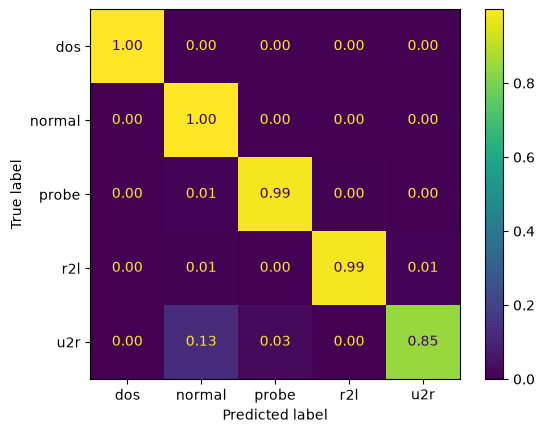

kategori  prediction
r2l       u2r           7
u2r       normal        5
dos       normal        4
normal    probe         4
          r2l           4
r2l       normal        4
normal    u2r           3
          dos           2
dtype: int64


In [5]:
print(classification_report(result[TARGET], result["prediction"], digits=3))
ConfusionMatrixDisplay.from_predictions(result[TARGET], result["prediction"], normalize="true",
                                        values_format=".2f")
plt.show()

wrong_rows = result[result["wrong"]]
swapped = wrong_rows.groupby([TARGET, "prediction"]).size()
print(swapped.sort_values(ascending=False).head(8))

## 2. Irisan data yang paling sering salah
Kolom kategori dipakai langsung. Kolom angka dipotong menjadi 5 kelompok sama banyak.

In [6]:
slices = []
for col in CAT_COLS + NUM_COLS:
    values = result[col]
    if col in NUM_COLS:
        values = pd.qcut(values, 5, duplicates="drop").astype(str)
    summary = result.groupby(values)["wrong"].agg(["mean", "size"])
    summary = summary[summary["size"] >= MIN_ROWS]
    for value, row in summary.iterrows():
        slices.append([col, value, row["size"], row["mean"]])

slices = pd.DataFrame(slices, columns=["kolom", "nilai", "jumlah", "persen_salah"])
print("rata-rata salah:", round(result["wrong"].mean(), 4))
worst_slices = slices.sort_values("persen_salah", ascending=False)
worst_slices.head(12).round(4)

rata-rata salah: 0.0024


,kolom,nilai,jumlah,persen_salah
14,service,telnet,116.0,0.0862
18,flag,RSTR,42.0,0.0476
8,service,ftp,290.0,0.0172
7,service,finger,66.0,0.0152
17,flag,RSTO,87.0,0.0115
6,service,ecr_i,119.0,0.0084
45,count,"(-0.001, 1.0]",3720.0,0.0075
9,service,ftp_data,883.0,0.0068
50,srv_count,"(-0.001, 2.0]",4887.0,0.0068
80,dst_host_same_src_port_rate,"(0.07, 1.0]",3082.0,0.0065


## 3. Yakin tapi salah, dan ragu
- Yakin tapi salah: curiga labelnya salah, atau kasus unik.
- Ragu: selisih probabilitas dua kelas teratas kecil (dekat batas kelas).

In [7]:
sorted_proba = np.sort(proba, axis=1)
result["top2_gap"] = sorted_proba[:, -1] - sorted_proba[:, -2]
confident_wrong = result[result["wrong"] & (result["confidence"] >= CONFIDENT)]
doubtful = result[result["top2_gap"] < DOUBT_GAP]
print("yakin tapi salah:", len(confident_wrong))
print("ragu:", len(doubtful), "| persen salah di baris ragu:", round(doubtful["wrong"].mean(), 3))
confident_wrong[[TARGET, "prediction", "confidence"] + CAT_COLS].head(10)

yakin tapi salah: 24
ragu: 6 | persen salah di baris ragu: 0.667


,kategori,prediction,confidence,protocol_type,service,flag
1232,u2r,normal,0.999992,udp,other,SF
1744,normal,r2l,0.959109,tcp,ftp,SF
1796,r2l,normal,0.992067,tcp,imap4,S1
2807,r2l,u2r,0.999971,tcp,ftp_data,SF
2880,probe,normal,0.997718,tcp,http,S2
4040,r2l,u2r,1.000000,tcp,telnet,SF
4456,normal,u2r,0.979987,tcp,telnet,SF
4696,r2l,u2r,0.963856,tcp,ftp_data,SF
5025,r2l,normal,0.915403,tcp,telnet,SF
5099,r2l,u2r,0.978909,tcp,ftp_data,SF


## 4. Feature yang paling berbeda: baris salah vs benar
Selisih rata-rata dibagi simpangan baku, supaya kolom dengan satuan berbeda bisa dibanding.

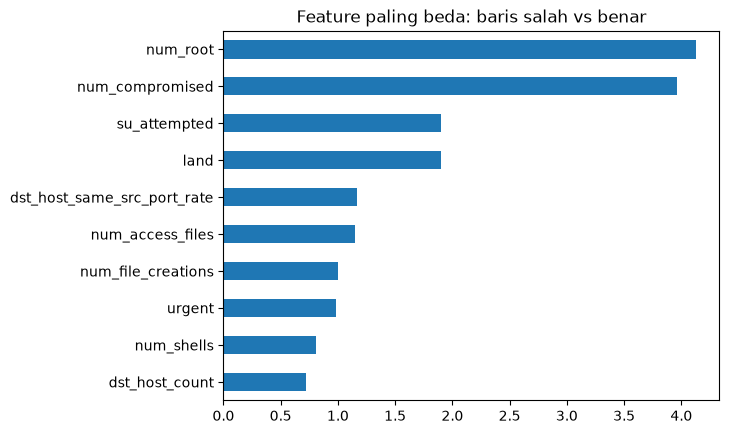

In [8]:
wrong_mean = result.loc[result["wrong"], NUM_COLS].mean()
right_mean = result.loc[~result["wrong"], NUM_COLS].mean()
difference = (wrong_mean - right_mean) / (result[NUM_COLS].std() + 1e-9)
difference = difference.abs().sort_values()
difference.tail(10).plot.barh()
plt.title("Feature paling beda: baris salah vs benar")
plt.show()

## Simpan tabel kesalahan (bahan laporan / cek manual)
Langkah lanjut umum: tambah feature untuk irisan terburuk, beri bobot kelas yang tertukar,
periksa ulang label baris "yakin tapi salah", atau atur threshold per kelas.

In [9]:
error_table = pd.DataFrame()
error_table["id"] = result[ID_COL]
error_table["label"] = result[TARGET]
error_table["prediksi"] = result["prediction"]
error_table["yakin"] = result["confidence"].round(4)
error_table["salah"] = result["wrong"]
error_table.to_csv("analisis_kesalahan.csv", index=False)
slices.to_csv("irisan_kesalahan.csv", index=False)
error_table[error_table["salah"]].head()

,id,label,prediksi,yakin,salah
1232,19101,u2r,normal,1.0000,True
1440,15279,dos,normal,0.4878,True
1744,3326,normal,r2l,0.9591,True
1779,1494,normal,dos,0.6878,True
1796,6329,r2l,normal,0.9921,True
